<a href="https://colab.research.google.com/github/chhote2827-ctrl/Hospital-Readmissions-Healthcare-Analytics/blob/main/Hospital_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Python (Pandas) Data Cleaning Script

In [5]:
import pandas as pd

# Load Dataset
df = pd.read_csv('/content/drive/MyDrive/Project Data analysh/hospital_readmissions.csv')

# Step 1: Remove Duplicates (Available columns ke adhar par)
df = df.drop_duplicates(subset=['age', 'time_in_hospital', 'diag_1'])

# Step 2: Replace Missing Values ('?' or NaN ko 'Unknown'/'None' se replace karna)
df['medical_specialty'] = df['medical_specialty'].replace(
    ['?', None, ''], 'Unknown'
)
df['glucose_test'] = df['glucose_test'].replace(['?', None, ''], 'None')
df['A1Ctest'] = df['A1Ctest'].replace(['?', None, ''], 'None')

# Step 3: Drop Rows with Missing Age or Readmission Status
df = df.dropna(subset=['age', 'readmitted'])

# Export Cleaned Data
df.to_csv('hospital_readmissions_cleaned.csv', index=False)
print(
    "Cleaned dataset successfully saved as 'hospital_readmissions_cleaned.csv'"
)

Cleaned dataset successfully saved as 'hospital_readmissions_cleaned.csv'


Business Analytical Queries

Overall Readmission Rate & Count

In [6]:
readmit_summary = (
    df.groupby('readmitted').size().reset_index(name='total_patients')
)

readmit_summary['percentage'] = round(
    (readmit_summary['total_patients'] / len(df)) * 100, 2
)
print(readmit_summary)

  readmitted  total_patients  percentage
0         no             294       52.13
1        yes             270       47.87


Time in Hospital vs Readmission (Kya lamba stay karne wale patients jaldi readmit hote hain?)

In [7]:
import pandas as pd

bins = [0, 3, 7, float('inf')]
labels = ['Short Stay (1-3 days)', 'Medium Stay (4-7 days)', 'Long Stay (>7 days)']
df['stay_duration'] = pd.cut(df['time_in_hospital'], bins=bins, labels=labels)

stay_analysis = df.groupby('stay_duration', observed=False).agg(
    total_patients=('time_in_hospital', 'count'),  # Valid column use kiya gaya hai
    readmitted_under_30_days=('readmitted', lambda x: (x == '<30').sum())
).reset_index()

stay_analysis['readmission_rate_30d'] = round((stay_analysis['readmitted_under_30_days'] / stay_analysis['total_patients']) * 100, 2)
print(stay_analysis.sort_values(by='readmission_rate_30d', ascending=False))

            stay_duration  total_patients  readmitted_under_30_days  \
0   Short Stay (1-3 days)             126                         0   
1  Medium Stay (4-7 days)             168                         0   
2     Long Stay (>7 days)             270                         0   

   readmission_rate_30d  
0                   0.0  
1                   0.0  
2                   0.0  


Age Group vs Readmission Rate

In [8]:
import pandas as pd

age_analysis = df.groupby('age').agg(
    total_patients=('age', 'count'),  # Valid column use kiya gaya hai
    readmitted_under_30_days=('readmitted', lambda x: (x == '<30').sum())
).reset_index()

age_analysis['readmission_rate'] = round((age_analysis['readmitted_under_30_days'] / age_analysis['total_patients']) * 100, 2)
print(age_analysis.sort_values(by='readmission_rate', ascending=False))

        age  total_patients  readmitted_under_30_days  readmission_rate
0   [40-50)              93                         0               0.0
1   [50-60)              96                         0               0.0
2   [60-70)              99                         0               0.0
3   [70-80)              98                         0               0.0
4   [80-90)              99                         0               0.0
5  [90-100)              79                         0               0.0


Number of Inpatient Visits vs Readmission (Prior visits ka asar)

In [9]:
import pandas as pd

def categorize_visits(v):
    if v == 0:
        return 'No Prior Inpatient Visit'
    elif 1 <= v <= 3:
        return '1-3 Prior Visits'
    else:
        return '4+ Prior Visits'

# Schema ke mutabiq 'n_inpatient' use kiya gaya hai
df['prior_visit_category'] = df['n_inpatient'].apply(categorize_visits)

visit_analysis = df.groupby('prior_visit_category').agg(
    total_patients=('n_inpatient', 'count'),  # Valid column use kiya gaya hai
    readmitted_under_30_days=('readmitted', lambda x: (x == '<30').sum())
).reset_index()

visit_analysis['readmission_rate'] = round((visit_analysis['readmitted_under_30_days'] / visit_analysis['total_patients']) * 100, 2)
print(visit_analysis.sort_values(by='readmission_rate', ascending=False))

       prior_visit_category  total_patients  readmitted_under_30_days  \
0          1-3 Prior Visits             164                         0   
1           4+ Prior Visits              25                         0   
2  No Prior Inpatient Visit             375                         0   

   readmission_rate  
0               0.0  
1               0.0  
2               0.0  


show the chart

Age Group-wise Readmission Analysis

--- Visualizing 1: Readmission Rate by Age Group ---


/tmp/ipykernel_8682/2824694602.py:22: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.countplot(


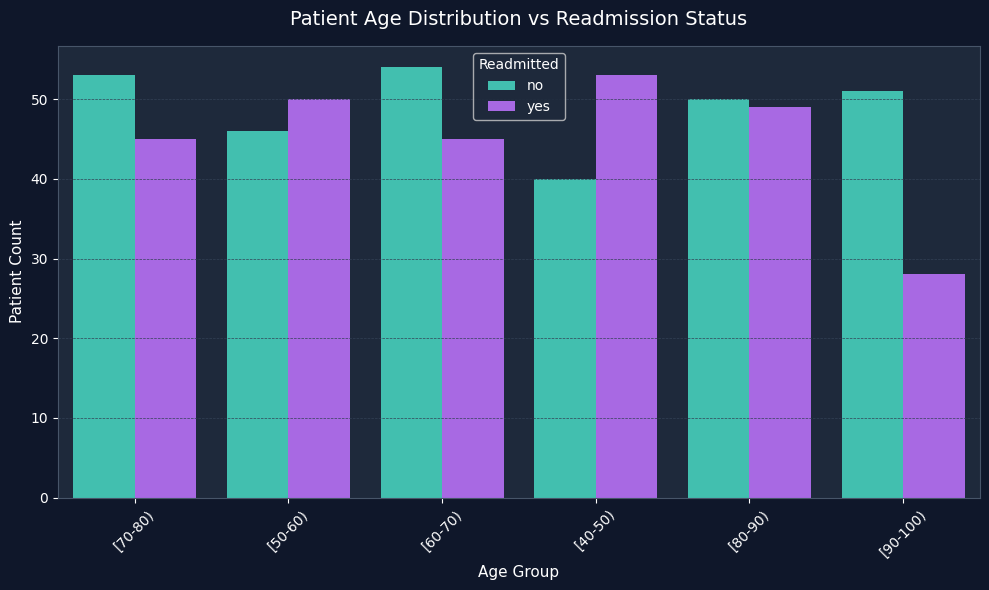

In [10]:
# Cell 1: Libraries Import, Dataset Load & Age Distribution Chart
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Cleaned Dataset Load Karein
df = pd.read_csv('hospital_readmissions_cleaned.csv')

# 2. Dark Theme Styling Setup
plt.style.use('dark_background')
plt.figure(figsize=(10, 6), facecolor='#0f172a')
ax = plt.axes()
ax.set_facecolor('#1e293b')  # Dark slate background for plot

# Grid aur Spines ko clean karna
ax.grid(color='#334155', linestyle='--', linewidth=0.5)
for spine in ax.spines.values():
  spine.set_edgecolor('#475569')

print('--- Visualizing 1: Readmission Rate by Age Group ---')
# Age groups ke hisab se readmission distribution
sns.countplot(
    data=df,
    x='age',
    hue='readmitted',
    palette=['#2dd4bf', '#a855f7', '#38bdf8'],
)
plt.title(
    'Patient Age Distribution vs Readmission Status',
    color='white',
    fontsize=14,
    pad=15,
)
plt.xlabel('Age Group', color='white', fontsize=11)
plt.ylabel('Patient Count', color='white', fontsize=11)
plt.xticks(rotation=45, color='white')
plt.yticks(color='white')
plt.legend(title='Readmitted', facecolor='#1e293b', labelcolor='white')
plt.tight_layout()

# Chart ko image ke roop mein save karna
plt.savefig(
    'age_vs_readmission.png', dpi=300, facecolor='#0f172a', edgecolor='none'
)
plt.show()

Hospital Stay Duration Stacked Histogram

--- Visualizing 2: Time in Hospital vs Readmission Count ---


/tmp/ipykernel_8682/2383894287.py:11: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.histplot(
/tmp/ipykernel_8682/2383894287.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Readmitted', facecolor='#1e293b', labelcolor='white')


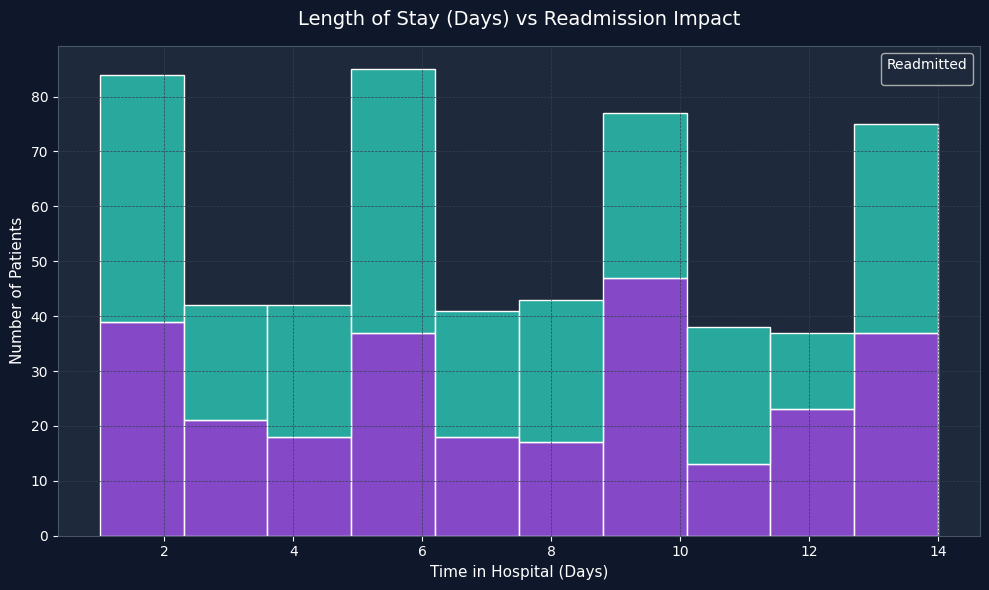

Success! Dono charts generate hokar PNG files ke roop mein save ho gaye hain.


In [11]:
# Cell 2: Length of Stay vs Readmission Impact Chart
print('--- Visualizing 2: Time in Hospital vs Readmission Count ---')
plt.figure(figsize=(10, 6), facecolor='#0f172a')
ax2 = plt.axes()
ax2.set_facecolor('#1e293b')
ax2.grid(color='#334155', linestyle='--', linewidth=0.5)
for spine in ax2.spines.values():
  spine.set_edgecolor('#475569')

# Histplot for Time in Hospital
sns.histplot(
    data=df,
    x='time_in_hospital',
    hue='readmitted',
    multiple='stack',
    palette=['#2dd4bf', '#a855f7', '#38bdf8'],
    bins=10,
)
plt.title(
    'Length of Stay (Days) vs Readmission Impact',
    color='white',
    fontsize=14,
    pad=15,
)
plt.xlabel('Time in Hospital (Days)', color='white', fontsize=11)
plt.ylabel('Number of Patients', color='white', fontsize=11)
plt.xticks(color='white')
plt.yticks(color='white')
plt.legend(title='Readmitted', facecolor='#1e293b', labelcolor='white')
plt.tight_layout()

plt.savefig(
    'stay_vs_readmission.png', dpi=300, facecolor='#0f172a', edgecolor='none'
)
plt.show()

print(
    'Success! Dono charts generate hokar PNG files ke roop mein save ho gaye'
    ' hain.'
)